# DeepInsight

In [43]:
%pip -q install git+https://github.com/alok-ai-lab/pyDeepInsight.git#egg=pyDeepInsight

Note: you may need to restart the kernel to use updated packages.


In [44]:
from pyDeepInsight import ImageTransformer
from pyDeepInsight.utils import Norm2Scaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
import pandas as pd
import numpy as np

## Data preprocessing
Read, normalize data and encode classes

In [45]:
#TODO combine in original file, labels and data
df = pd.read_csv("../dataset/psa_spectral_ratio.csv") 
labels = pd.read_csv("../dataset/psa_labels.csv")[["file", "soil_type"]]
df = df.merge(labels, left_on='ext_station_key', right_on='file', how="left")
df = df[df["orientation"] == "H/V"]
df = df.drop(columns=["station_key", "index","orientation", "file"]).set_index(["ext_station_key"])

In [46]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,991,992,993,994,995,996,997,998,999,soil_type
ext_station_key,,,,,,,,,,,,,,,,,,,,,
ACAP8509191,1.832417,0.979014,0.706718,0.765552,0.920088,0.908694,0.829887,0.908802,1.145063,1.184865,...,0.312101,0.311689,0.311291,0.310899,0.310504,0.310123,0.309745,0.309366,0.309002,other
ACAS8509191,1.491663,1.504850,1.491579,1.464569,1.455796,1.482345,1.493439,1.514120,1.554327,1.532028,...,1.404868,1.406772,1.408692,1.410619,1.412563,1.414514,1.416472,1.418447,1.420419,other
APAT8509191,2.385887,2.234682,2.385794,2.186408,2.375262,2.267683,2.365453,1.995741,1.671990,1.804774,...,1.314710,1.316518,1.317718,1.318986,1.320310,1.321590,1.322727,1.323830,1.324829,unknown
ATYC8509191,1.332917,1.321993,1.338182,1.347106,1.338160,1.405286,1.329343,1.297113,1.432604,1.290530,...,2.766445,2.765736,2.764842,2.763547,2.761962,2.760014,2.757791,2.755195,2.752101,roca
AZIH8509191,1.831220,1.804801,1.826030,1.650215,1.395968,1.533544,1.624512,1.593834,1.719605,1.590238,...,1.649583,1.652074,1.654785,1.657510,1.660188,1.662917,1.665774,1.668528,1.671449,roca


In [47]:
X = df.drop(columns=["soil_type"])
y = df["soil_type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Map from pandas to numpy
X_train = X_train.values
X_test = X_test.values
y_train = y_train.values
y_test = y_test.values

In [48]:
ln = Norm2Scaler()
X_train_norm = ln.fit_transform(X_train)
X_test_norm = ln.transform(X_test)

In [49]:
X_train_norm

array([[0.38381045, 0.38130415, 0.37716683, ..., 0.37054318, 0.37058657,
        0.37058928],
       [0.3648522 , 0.35959646, 0.35735078, ..., 0.33640229, 0.33616709,
        0.33592522],
       [0.4256871 , 0.42330927, 0.42191805, ..., 0.31268479, 0.31288257,
        0.31314475],
       ...,
       [0.38748901, 0.38598531, 0.38171146, ..., 0.38848494, 0.38762759,
        0.3867566 ],
       [0.41816791, 0.41940668, 0.41222333, ..., 0.40406831, 0.40265797,
        0.40127507],
       [0.40124863, 0.39534885, 0.40492999, ..., 0.45282262, 0.45339088,
        0.4539641 ]])

In [50]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

In [51]:
distance_metric = 'cosine'
reducer = TSNE(
    n_components=2,
    metric=distance_metric,
    init='random',
    learning_rate='auto',
    n_jobs=-1
)

In [52]:
image_size = (30, 30)
it = ImageTransformer(
    feature_extractor=reducer, 
    pixels=image_size)

Train image transformer on training data and transform training and testing sets. Values should be between 0 and 1.

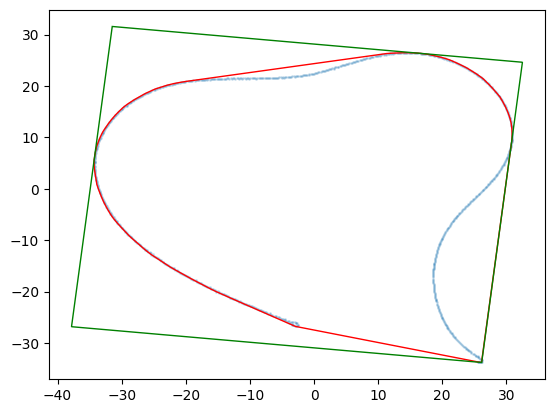

In [53]:
it.fit(X_train_norm, y=y_train, plot=True)
X_train_img = it.transform(X_train_norm)
X_test_img = it.transform(X_test_norm)

The feature density matrix can be extracted from the trained transformer in order to view overall feature overlap.

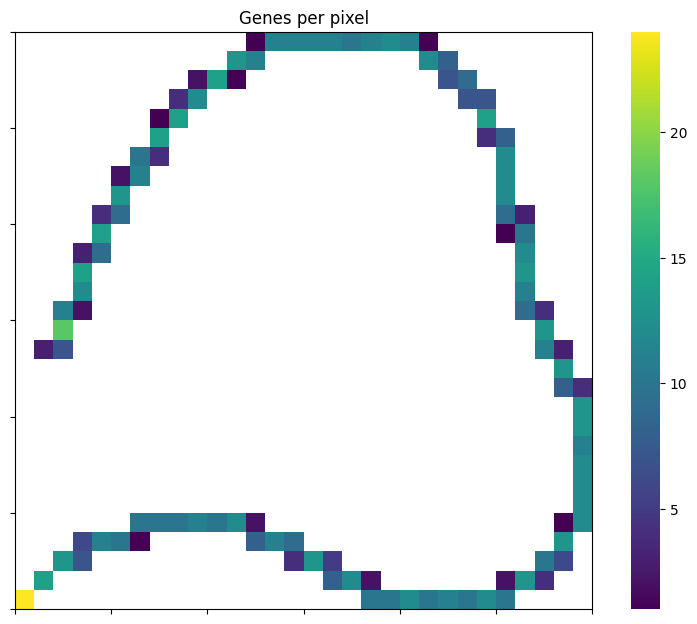

In [54]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

fdm = it.feature_density_matrix()
fdm[fdm == 0] = np.nan

plt.figure(figsize=(10, 7.5))

ax = sns.heatmap(fdm, cmap="viridis", linewidths=0., 
                 linecolor="lightgrey", square=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
for _, spine in ax.spines.items():
    spine.set_visible(True)
_ = plt.title("Genes per pixel")

Plots for the image matrices first six samples of the training set.

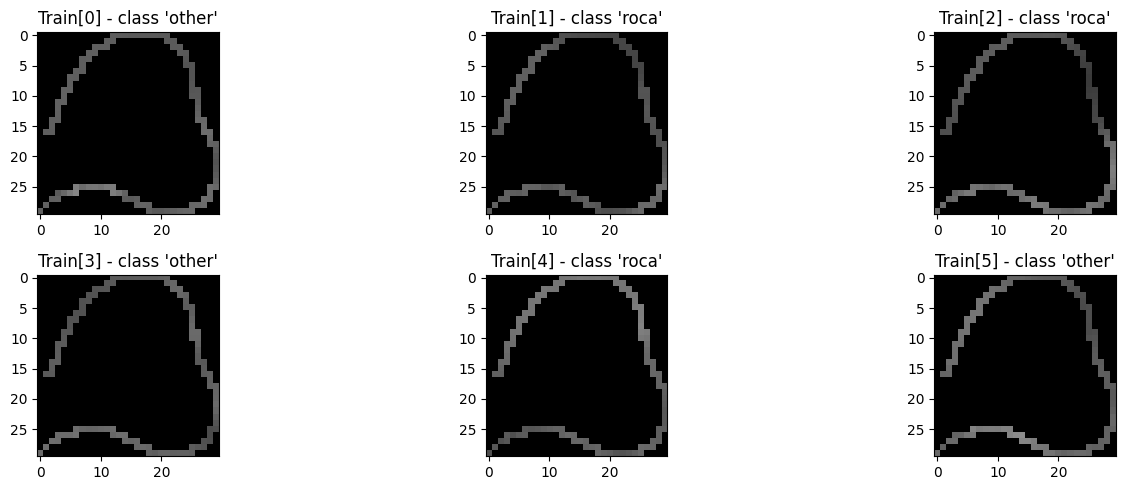

In [55]:
fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()
for i in range(6):
    ax[i].imshow(X_train_img[i])
    ax[i].title.set_text(f"Train[{i}] - class '{y_train[i]}'")
plt.tight_layout()

Plots for the image matrices first six samples of the test set.

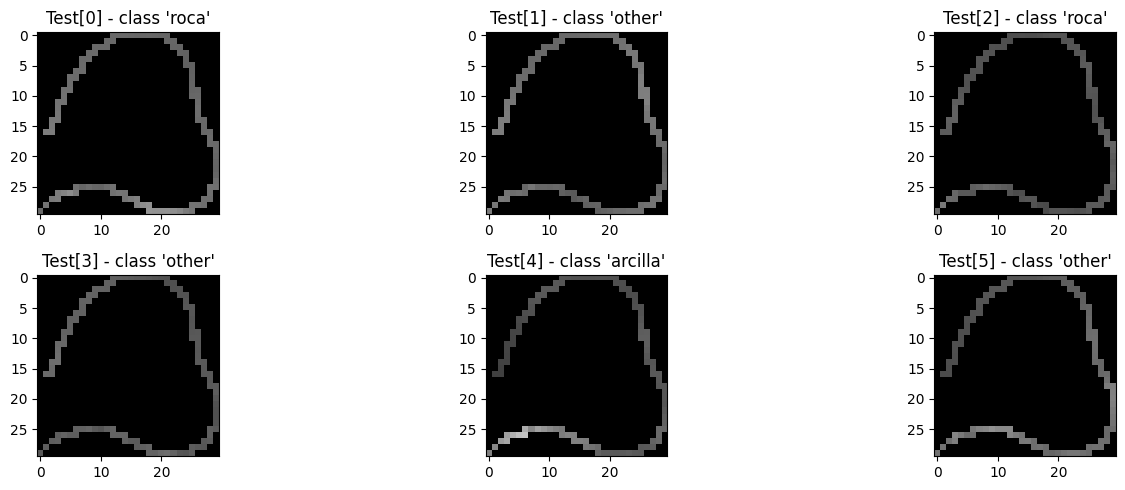

In [56]:
X_test_img = it.transform(X_test_norm)

fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()
for i in range(6):
    ax[i].imshow(X_test_img[i])
    ax[i].title.set_text(f"Test[{i}] - class '{y_test[i]}'")
plt.tight_layout()

## Fitting a CNN model

In [57]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [58]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)  # Output size: 16x15x15
        self.dropout1 = nn.Dropout(0.25)  # Dropout added for regularization
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # Output size: 32x7x7
        self.dropout2 = nn.Dropout(0.25)  # Another dropout layer for regularization
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.dropout1(x)
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.dropout2(x)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [59]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float()
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float()
y_test_tensor = torch.from_numpy(le.transform(y_test))

In [60]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [61]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-04,
    weight_decay=1e-05
)

In [63]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 1.770
[20] loss: 1.174
[40] loss: 1.063
[60] loss: 1.027
[80] loss: 1.022
[99] loss: 1.005


In [64]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.641
The test accuracy was 0.645


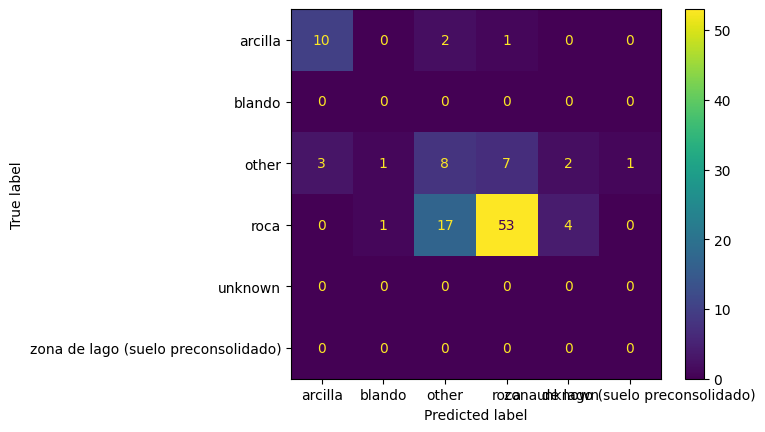

In [65]:
_ = ConfusionMatrixDisplay.from_predictions(test_predicted, y_test_tensor, display_labels=le.classes_)